# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [15]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df_excel = pd.read_excel("./data/Survey response sheet (1).xlsx")

# exportation en format CSV
df_excel.to_csv("donnees_brutes.csv", index=False)
print(" Conversion terminée : 'votre_fichier.xlsx' -> 'donnees_brutes.csv'\n")

 Conversion terminée : 'votre_fichier.xlsx' -> 'donnees_brutes.csv'



In [6]:
df = pd.read_csv("donnees_brutes.csv")

print("--- 1. APERÇU ET DIAGNOSTIC INITIAL ---")
print(f"Dimensions du dataset : {df.shape[0]} lignes, {df.shape[1]} colonnes\n")
print(df.info())
print("\nAperçu des valeurs manquantes :")
print(df.isnull().sum())

--- 1. APERÇU ET DIAGNOSTIC INITIAL ---
Dimensions du dataset : 1000 lignes, 82 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 82 columns):
 #   Column                                                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                                                  --------------  -----  
 0   Timestamp                                                                                                                               1000 non-null   str    
 1   Participant ID                                                                                                                          1000 non-null   str    
 2   Age                                                                                                                                     1000 non-null 

In [11]:
import pandas as pd
import numpy as np

print("\n--- 2. NETTOYAGE ET IMPUTATION SÉCURISÉE ---")

# 1. Supprimer les doublons
nb_doublons = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Nombre de doublons supprimés : {nb_doublons}")

# 2. Conversion et séparation des colonnes
num_cols = []
cat_cols = []

for col in df.columns:
    # Tenter la conversion numérique
    converted = pd.to_numeric(df[col], errors='coerce')
    # Si la colonne contient des chiffres valides et n'est pas purement du texte
    if converted.notna().sum() > 0 and df[col].dtype != 'object':
        df[col] = converted
        num_cols.append(col)
    else:
        cat_cols.append(col)

print(f"Colonnes numériques ({len(num_cols)}) : {num_cols}")
print(f"Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}")

# 3. Imputation NUMÉRIQUE par la Médiane (100% Pandas)
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# 4. Imputation CATÉGORIELLE par le Mode / Valeur la plus fréquente (100% Pandas)
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        # Prendre la première valeur la plus fréquente (mode)
        mode_val = df[col].mode()[0] if not df[col].mode().empty else "Non renseigné"
        df[col] = df[col].fillna(mode_val)

print(f"\n Imputation réussie ! Valeurs manquantes restantes : {df.isnull().sum().sum()}")


--- 2. NETTOYAGE ET IMPUTATION SÉCURISÉE ---
Nombre de doublons supprimés : 0
Colonnes numériques (12) : ['Timestamp', 'Age', '1.b) Painful menstruation', '1.c) If painful, then pain lasts up to how many days?', '1.d) Menstrual flow', '1.f) Bleeding time in a month', '1.g) Age at menopause ', '1.h) Post menopausal bleeding', '2.a) If yes, then no. of children', '2.c) Gap between first and second child', '3.a) If miscarriage, then number of miscarriages', '3.c) If abortion, then number of abortions']
Colonnes catégorielles (70) : ['Participant ID', 'Unnamed: 3', 'Q1. Do you know about cancer?', 'Q1. (a) If yes, then which cancer do you know about?', '(b) What was the source of information?', 'Q2. Do you know that cancer can affect any organ of the body?', "Q3. Have you ever heard about cancer of cervix/cervical cancer? (Cervix is commonly known as 'mouth of uterus')", 'Q3.a) If yes, then do you know that only women are affected?', 'Q.3b) Do you know about signs and symptoms of this can

In [12]:
print("\n--- 3. TRAITEMENT DES OUTLIERS ---")

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Plafonnement des valeurs (Clipping)
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("Valeurs extrêmes plafonnées avec succès.")


--- 3. TRAITEMENT DES OUTLIERS ---
Valeurs extrêmes plafonnées avec succès.


In [13]:
print("\n--- 4. ENCODAGE ET STANDARDISATION ---")

# One-Hot Encoding des variables textuelles
if len(cat_cols) > 0:
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Standardisation des variables
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# Export final du dataset prétraité
df_scaled.to_csv("dataset_pretraite.csv", index=False)
print(" Dataset propre et préparé exporté sous 'dataset_pretraite.csv' !")



--- 4. ENCODAGE ET STANDARDISATION ---
 Dataset propre et préparé exporté sous 'dataset_pretraite.csv' !


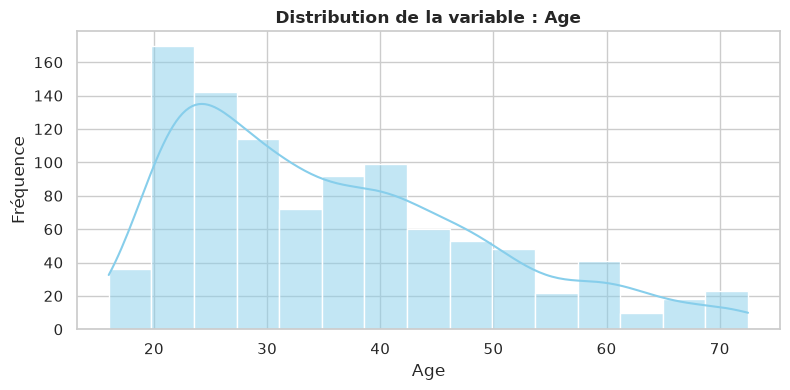

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# Affichage unique de la distribution de l'Âge
if 'Age' in df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df['Age'], kde=True, color="skyblue", bins=15)
    plt.title("Distribution de la variable : Age", fontsize=12, fontweight='bold')
    plt.xlabel("Age")
    plt.ylabel("Fréquence")
    plt.tight_layout()
    plt.show()